# SPY 增强策略：最终结果阅读

最终展示方案按已完成 12 组中的测试期净年化收益最高者选择。这是事后选择的探索性结果；本 notebook 只读取保存数据，不训练模型、不执行交易回放。

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / 'results/backtest/spy_overlay_final_20261101').is_dir())
BASE = ROOT / 'results/backtest/spy_overlay_final_20261101'
selection = json.loads((BASE / 'selection_record.json').read_text(encoding='utf-8'))
assert selection['ex_post_selection'] and not selection['strategy_replayed']
display(Markdown(f"**最终展示：{selection['model'].upper()} {selection['scheme']}，{selection['entry_bps']:g}／{selection['exit_bps']:g} bp**"))
print('按已观察的测试期成本后净年化收益选择；没有新增参数或回放。')

按已观察的测试期成本后净年化收益选择；没有新增参数或回放。


**最终展示：GBDT S1，15／7.5 bp**

In [2]:
summary = pd.read_csv(BASE / 'selected_and_benchmarks.csv')
fields = ['split','series_id','annualized_net_return','annualized_net_volatility','max_drawdown','cumulative_relative_to_spy_reinvest']
table = summary[fields].copy()
for col in fields[2:]: table[col] = table[col].map(lambda x: f'{x:.3%}')
display(table)
print('两阶段独立初始化；相对表现为期末财富比减一。')

两阶段独立初始化；相对表现为期末财富比减一。


,split,series_id,annualized_net_return,annualized_net_volatility,max_drawdown,cumulative_relative_to_spy_reinvest
0,validation,overlay_15_gbdt_S1,11.083%,20.473%,-30.689%,9.666%
1,validation,spy_buy_hold,8.800%,19.358%,-31.023%,-1.126%
2,validation,spy_reinvest,9.047%,20.162%,-32.055%,0.000%
3,validation,cash,1.316%,0.099%,0.000%,-30.704%
4,test,overlay_15_gbdt_S1,22.723%,15.576%,-19.303%,2.163%
5,test,spy_buy_hold,21.672%,14.896%,-19.261%,-1.053%
6,test,spy_reinvest,22.019%,15.239%,-19.764%,0.000%
7,test,cash,4.808%,0.186%,0.000%,-43.184%


In [3]:
ranked = pd.read_csv(BASE / 'all_12_candidates_ranked.csv')
assert len(ranked) == 12 and ranked.iloc[0]['series_id'] == selection['series_id']
fields = ['test_return_rank','series_id','annualized_net_return','validation_annualized_net_return','selected_for_final_presentation']
table = ranked[fields].copy()
for col in ['annualized_net_return','validation_annualized_net_return']:
    table[col] = table[col].map(lambda x: f'{x:.3%}')
display(table)
print('完整保留其他组合，不仅展示收益最高者。')

完整保留其他组合，不仅展示收益最高者。


,test_return_rank,series_id,annualized_net_return,validation_annualized_net_return,selected_for_final_presentation
0,1,overlay_15_gbdt_S1,22.723%,11.083%,True
1,2,overlay_15_gbdt_S2,22.616%,10.676%,False
2,3,overlay_10_gbdt_S2,22.464%,10.865%,False
3,4,overlay_15_elastic_net_S0,21.884%,9.137%,False
4,5,overlay_15_elastic_net_S1,21.884%,8.942%,False
5,6,overlay_15_elastic_net_S2,21.884%,8.942%,False
6,7,overlay_10_gbdt_S1,21.851%,11.434%,False
7,8,overlay_10_elastic_net_S0,21.728%,7.888%,False
8,9,overlay_10_elastic_net_S1,21.728%,8.103%,False
9,10,overlay_10_elastic_net_S2,21.728%,8.103%,False


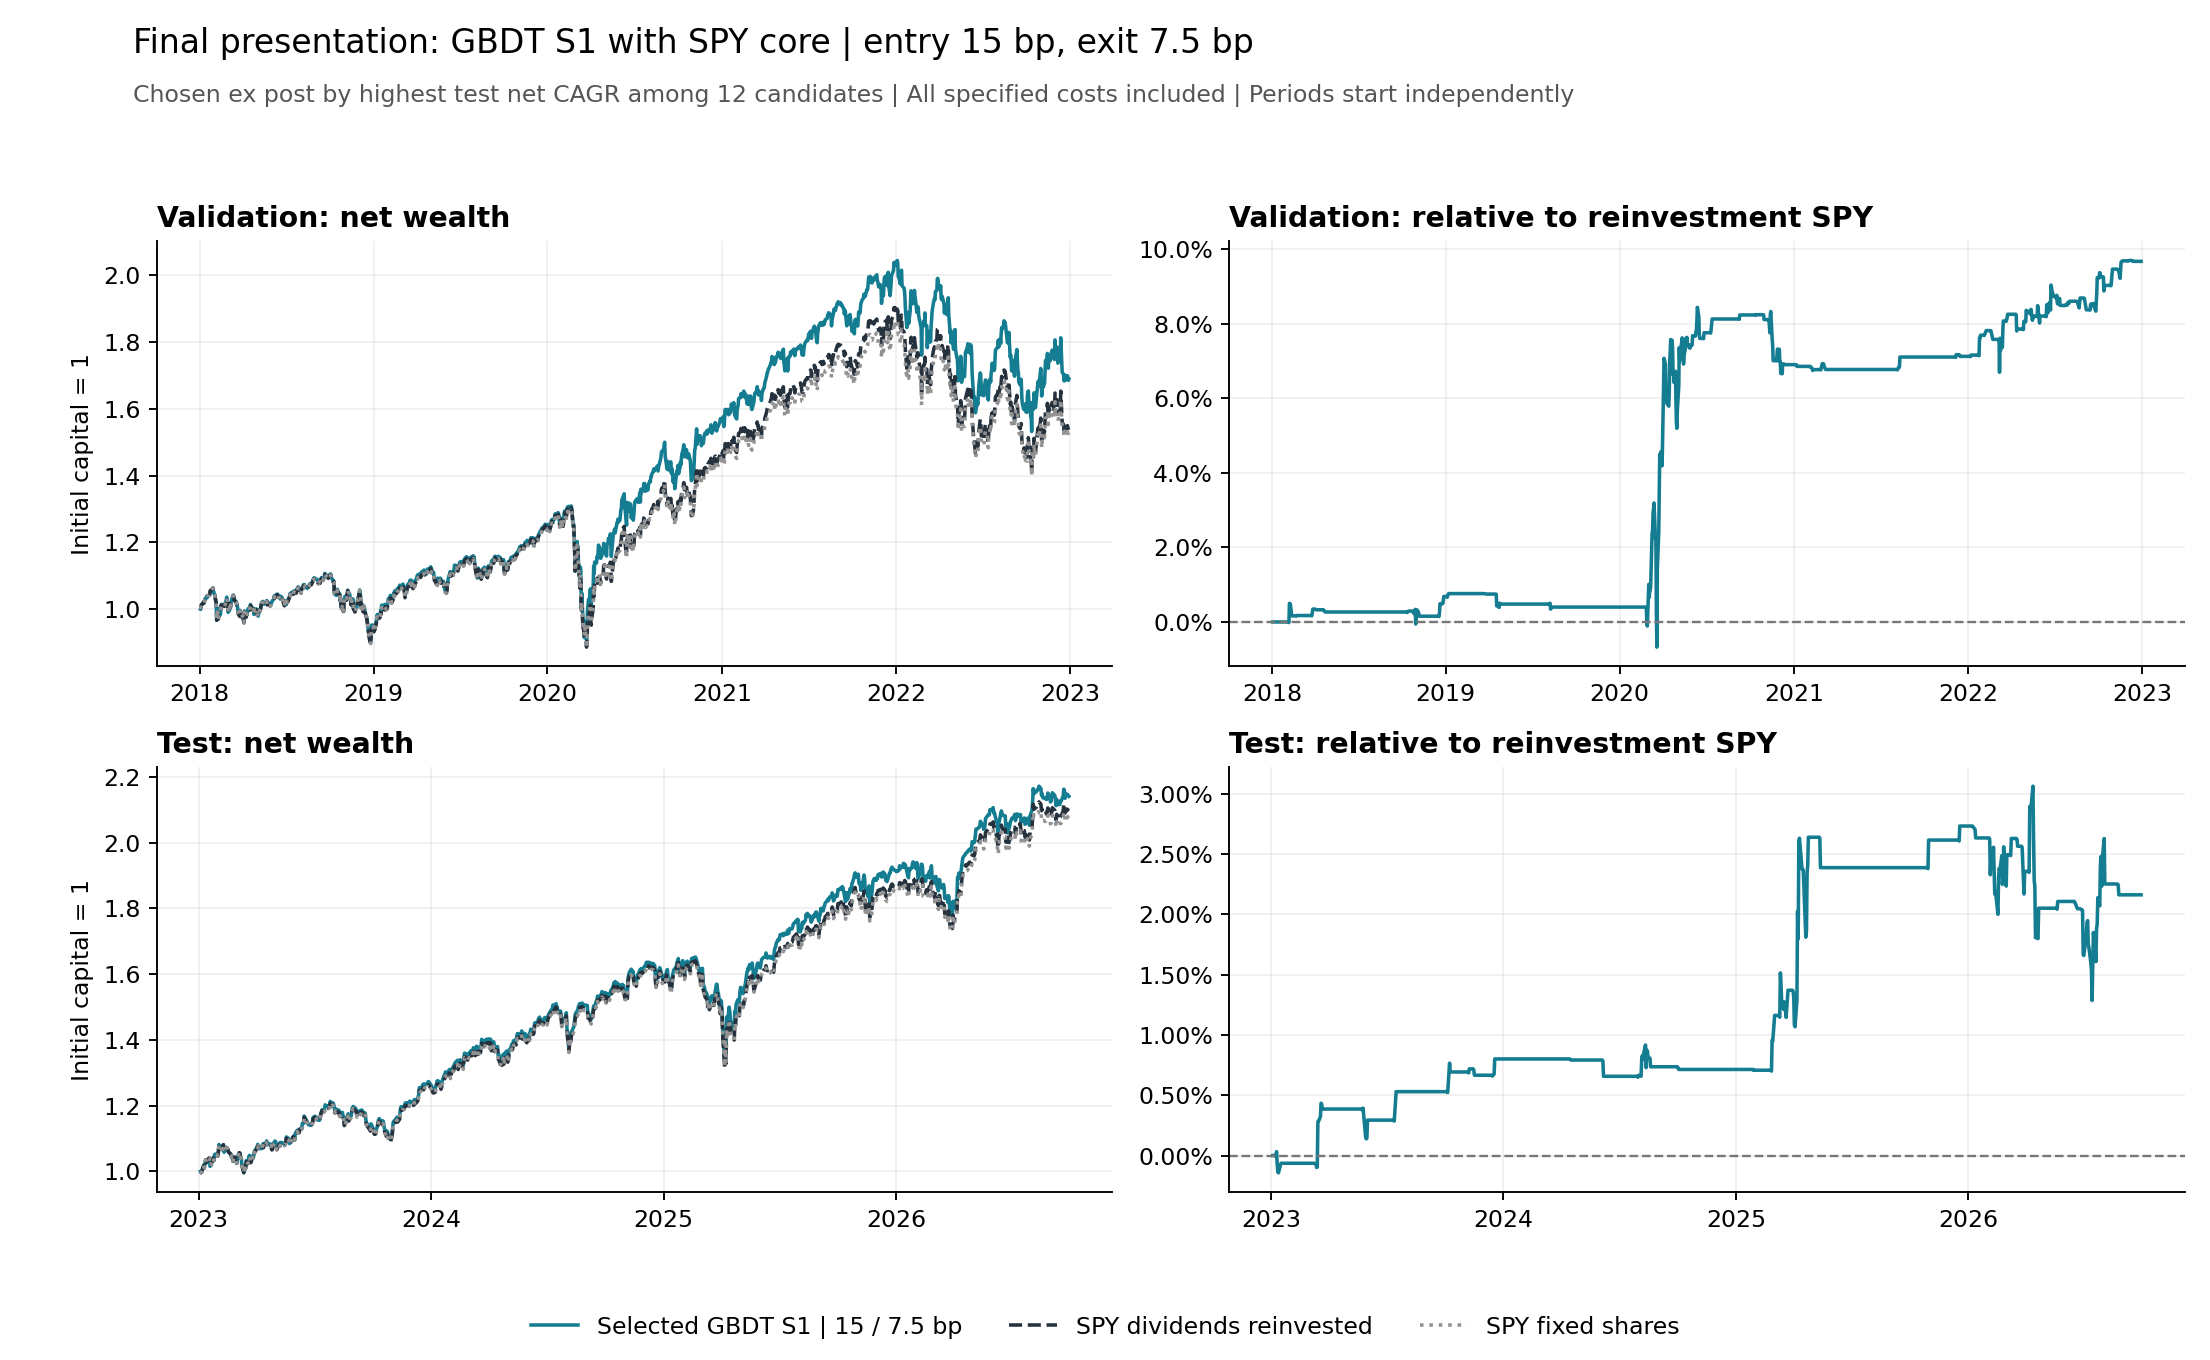

In [4]:
display(Image(filename=str(BASE / 'selected_strategy.png')))

In [5]:
yearly = pd.read_csv(BASE / 'selected_yearly_returns.csv')
table = yearly[['split','year','partial_year','net_period_return','spy_reinvest_period_return','relative_period_return']].copy()
for col in ['net_period_return','spy_reinvest_period_return','relative_period_return']:
    table[col] = table[col].map(lambda x: f'{x:.3%}')
display(table)
print('2026 年仅截至 9 月 30 日；此处不将部分年度收益再年化。')

2026 年仅截至 9 月 30 日；此处不将部分年度收益再年化。


,split,year,partial_year,net_period_return,spy_reinvest_period_return,relative_period_return
0,validation,2018,False,-4.835%,-5.482%,0.684%
1,validation,2019,False,30.494%,30.865%,-0.284%
2,validation,2020,False,25.783%,18.137%,6.472%
3,validation,2021,False,29.919%,29.649%,0.208%
4,validation,2022,False,-16.760%,-18.693%,2.377%
5,test,2023,False,27.216%,26.205%,0.801%
6,test,2024,False,25.288%,25.396%,-0.087%
7,test,2025,False,20.212%,17.849%,2.005%
8,test,2026,True,11.752%,12.376%,-0.555%


In [6]:
selected = summary.loc[summary['series_id'].eq(selection['series_id'])].copy()
fields = ['split','sector_participation','mean_holding_intervals','mean_gross_exposure','max_gross_exposure',
          'annualized_two_sided_turnover','total_execution_fee','total_borrow_fee','total_financing_interest','total_cost']
display(selected[fields])
print('成本金额均以初始资金 1 为单位，累计金额不是年化费率。所有计算来自已保存账本。')

成本金额均以初始资金 1 为单位，累计金额不是年化费率。所有计算来自已保存账本。


,split,sector_participation,mean_holding_intervals,mean_gross_exposure,max_gross_exposure,annualized_two_sided_turnover,total_execution_fee,total_borrow_fee,total_financing_interest,total_cost
0,validation,0.171042,2.234973,1.039379,1.5,15.448456,0.032518,0.001397,0.002915,0.036830
4,test,0.131270,2.135135,1.023212,1.5,9.546884,0.016907,0.000680,0.003538,0.021125
